# Comet outgassing: the rocket effect on 2P/Encke

**The question.** Near perihelion a comet's ice sublimates and the escaping gas pushes back on the
nucleus. That *non-gravitational* acceleration is thousands of times larger than an asteroid's
Yarkovsky push. An orbit computed from gravity alone drifts away from the comet within a single
return. How big is the push on 2P/Encke (the comet with the shortest known period, 3.3 years),
which way does it point, and do we get the same answer as JPL?

PyRoOrb uses the standard Marsden et al. (1973) model: radial, transverse and normal accelerations
$A_1, A_2, A_3$ (au/day²) scaled by the water-sublimation curve $g(r)$, which switches the force on
inside ~3 au. For a comet designation, every fit tries gravity-only, then $A_1$, $A_1A_2$ and
$A_1A_2A_3$, and keeps the richest model the data justify.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## 1. Fetch, and keep the recent apparitions

Encke has been observed since the 18th century, but its outgassing changes from one return to the
next, so no single set of constant $A$'s spans two centuries. (A fit of the whole archive is also
slow.) We keep the same span JPL's current solution uses: November 2018 onward, the 2020, 2023 and
2026–27 returns. The radar list is cut to the same span.

In [2]:
from astropy.time import Time

everything = pyroorb.fetch_observations("2P")
cut = Time("2018-11-01").jd
obs = everything.select(start=cut)
print(f"{len(everything)} observations in the archive, {len(obs)} since 2018-11")

6953 observations in the archive, 1799 since 2018-11


## 2. The automatic fit

In [3]:
fit = pyroorb.fit_orbit(obs, designation="2P")
print(f"{fit.n_observations()}/{fit.n_total_observations()} observations kept, rms {fit.rms_residual():.3f}\", "
      f"{fit.n_oppositions()} apparitions, model: {fit.nongrav_model}")
for k, v in fit.nongrav_params.items():
    lo, hi = fit.rational_nongrav_intervals()[k]
    print(f"  {k} = {v:+.3e}  (-{lo:.1e} / +{hi:.1e}) au/day^2   [{abs(v) / lo:.0f} sigma]")

disc = fit.nongrav_discovery["comet"]       # the model ladder it climbed (internal API, may change)
base = disc["compare_base"]
print(f"\n{'model':8s} {'rms':>6s} {'chi2':>9s} {'dBIC':>7s}  coefficients      (N = {base['N']} residuals)")
print(f"{'gravity':8s} {disc['rms0']:6.3f} {base['chi2_0']:9.1f}")
prev, k_prev = base["chi2_0"], 6
for name, m in disc["compare"].items():
    k = 6 + len(m["params"])
    dbic = (prev - m["chi2"]) - (k - k_prev) * np.log(base["N"])    # gain over the previous rung
    print(f"{name:8s} {m['rms']:6.3f} {m['chi2']:9.1f} {dbic:7.1f}  "
          + ", ".join(f"{k}={v:.2e}" for k, v in m["params"].items()))
    prev, k_prev = m["chi2"], k

1643/1799 observations kept, rms 0.584", 9 apparitions, model: comet3


  A1 = +7.970e-11  (-2.1e-11 / +2.0e-11) au/day^2   [4 sigma]
  A2 = +5.648e-12  (-2.0e-13 / +2.0e-13) au/day^2   [28 sigma]
  A3 = +9.110e-10  (-1.7e-10 / +1.7e-10) au/day^2   [5 sigma]

model       rms      chi2    dBIC  coefficients      (N = 3594 residuals)
gravity   1.155   16543.8
comet1    1.098   15268.7  1266.9  A1=5.16e-10
comet2    1.046   13052.0  2208.5  A1=3.36e-11, A2=7.11e-12
comet3    1.055   12708.2   335.7  A1=2.04e-11, A2=7.35e-12, A3=1.33e-09


**Why comet3, when its rms is higher than comet2's?** The model ladder does not compare rms. It
climbs one rung at a time and accepts a rung only if its **weighted χ²** improves on the previous
rung by more than the BIC penalty for the added parameter, with a margin of 15, and a nested
F-test agrees. The rms column is unweighted: a model can lower χ² by fitting the precise
observations better while the noisier ones move the other way. comet3 beats comet2 by hundreds in
χ² here. After the outlier-rejection round, the engine re-tests on the final observation set,
where the gain is smaller but still clears the margin.

**What $A_3$ is probably absorbing.** Passing the test is not the same as being physical. The
fitted $A_3$ (out of the orbital plane) comes out ten times larger than $A_1$ (radial), which is
odd for a real outgassing force. A likelier reading is that Encke's outgassing is **asymmetric
about perihelion**, and the symmetric Marsden law cannot represent that. The free $A_3$ soaks up
part of the asymmetry and pulls $A_2$ with it. (Asymmetry is usually modelled with a time offset
of the outgassing peak, which PyRoOrb's ladder does not offer yet.) JPL's solution fits $A_1$ and
$A_2$ only, and quotes uncertainties about twice ours, which suggests looser observation weights; at
such weights the $A_3$ gain would likely not clear
such a bar. So the like-for-like check against JPL in section 4 is the two-parameter model.

## 3. What gravity alone does: it throws observations away

A gravity-only fit (`fit_orbit(..., nongrav="none")`, non-gravitational discovery off) can
still return a small rms. It gets there by **rejecting** the observations it cannot fit, and those
pile up where the comet is most active. The plot shows every observation's residual under each
orbit; perihelion passages are marked.

gravity only: 1576/1799 kept, rms 0.579"
outgassing  : 1643/1799 kept, rms 0.584"


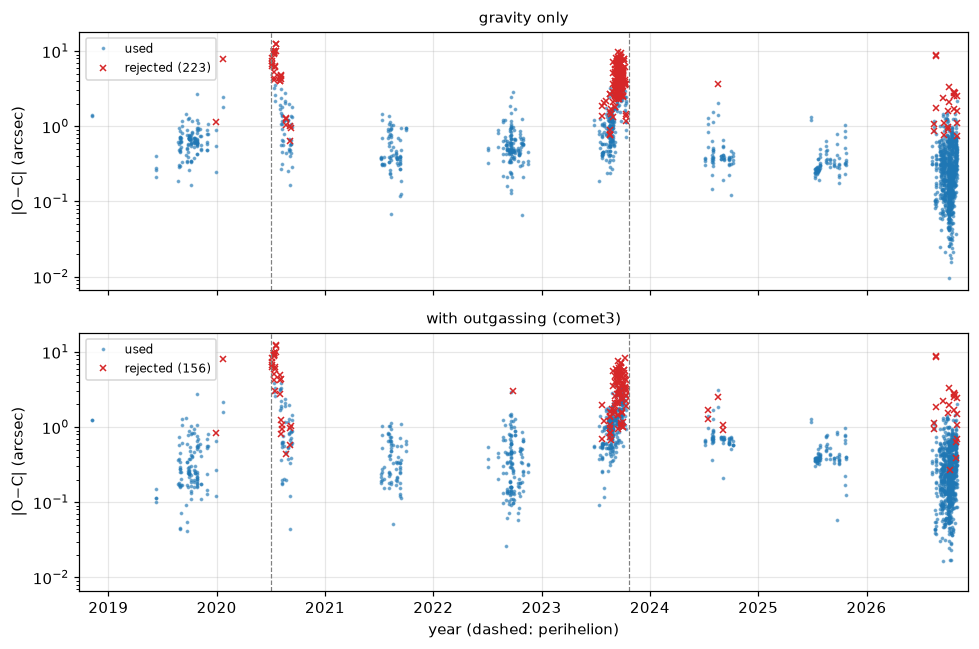

In [4]:
grav = pyroorb.fit_orbit(obs, designation="2P", nongrav="none")      # gravity only
print(f"gravity only: {grav.n_observations()}/{grav.n_total_observations()} kept, rms {grav.rms_residual():.3f}\"")
print(f"outgassing  : {fit.n_observations()}/{fit.n_total_observations()} kept, rms {fit.rms_residual():.3f}\"")

tp, period = fit.elements()["Tp"], fit.elements()["P"] * 365.25
perihelia = [tp + k * period for k in range(-2, 2)]
yr = lambda jd: Time(jd, format="jd").decimalyear

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, sharey=True)
for ax, f, title in ((axes[0], grav, "gravity only"), (axes[1], fit, f"with outgassing ({fit.nongrav_model})")):
    res = f.residuals()
    t = yr(np.array([r["jd_utc"] for r in res]))
    tot = np.array([np.hypot(r["d_ra_arcsec"], r["d_dec_arcsec"]) for r in res])
    inc = np.array([r["included"] for r in res])
    ax.semilogy(t[inc], tot[inc], ".", ms=3, alpha=0.5, label="used")
    ax.semilogy(t[~inc], tot[~inc], "x", ms=4, color="C3", label=f"rejected ({(~inc).sum()})")
    for p in perihelia:
        ax.axvline(yr(p), color="0.5", ls="--", lw=0.8)
    ax.set_title(title, fontsize=10); ax.set_ylabel("|O−C| (arcsec)"); ax.legend(fontsize=8, loc="upper left")
axes[1].set_xlim(yr(cut) - 0.1, yr(max(r["jd_utc"] for r in res)) + 0.1)
axes[1].set_xlabel("year (dashed: perihelion)"); plt.tight_layout(); plt.show()

## 4. Compare with JPL

JPL's current solution for Encke fits $A_1$ and $A_2$ only. For a like-for-like comparison we also
force that two-parameter model onto the gravity fit's observation set
(`fit_orbit(..., nongrav="comet2")`).

JPL orbit K273/25 data 2018-11-05 to 2026-10-28


JPL (A1, A2)                      A1 = 7.743e-11 ± 4.0e-11  A2 = 3.438e-12 ± 4.3e-13
PyRoOrb comet2, strict obs set    A1 = 1.059e-10 ± 2.1e-11  A2 = 3.297e-12 ± 2.1e-13
PyRoOrb automatic (comet3)        A1 = 7.970e-11 ± 2.1e-11  A2 = 5.648e-12 ± 2.0e-13  A3 = 9.110e-10 ± 1.7e-10


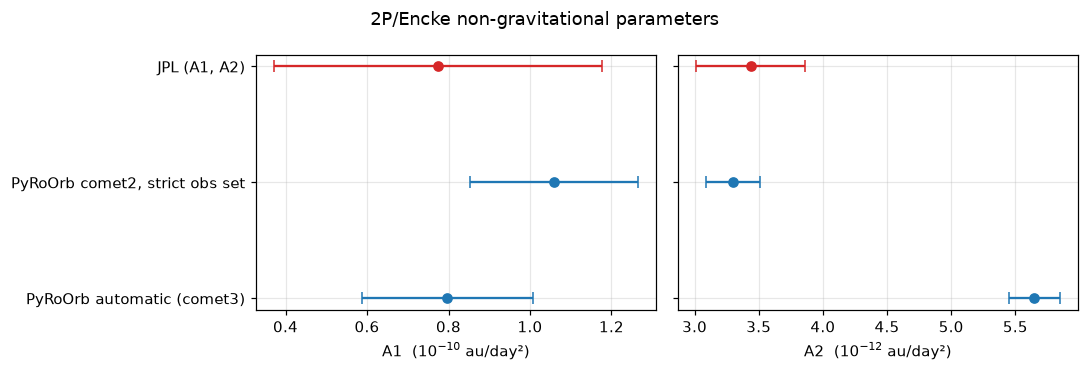

In [5]:
import json, urllib.request

sbdb = json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/sbdb.api?sstr=2P"))
jpl = {p["name"]: (float(p["value"]), float(p["sigma"])) for p in sbdb["orbit"]["model_pars"]}
print("JPL orbit", sbdb["orbit"]["orbit_id"], "data", sbdb["orbit"]["first_obs"], "to", sbdb["orbit"]["last_obs"])

c2 = pyroorb.fit_orbit(obs, designation="2P", nongrav="comet2")
sol = {"JPL (A1, A2)": {k: jpl[k] for k in ("A1", "A2")},
       "PyRoOrb comet2, strict obs set": {k: (v, c2.rational_nongrav_intervals()[k][0])
                                          for k, v in c2.nongrav_params.items()},
       f"PyRoOrb automatic ({fit.nongrav_model})": {k: (v, fit.rational_nongrav_intervals()[k][0])
                                                    for k, v in fit.nongrav_params.items()}}
for name, d in sol.items():
    print(f"{name:34s}" + "  ".join(f"{k} = {v:.3e} ± {s:.1e}" for k, (v, s) in d.items()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, k, scale in ((axes[0], "A1", 1e-10), (axes[1], "A2", 1e-12)):
    for j, (name, d) in enumerate(sol.items()):
        if k in d:
            ax.errorbar(d[k][0] / scale, j, xerr=d[k][1] / scale, fmt="o", capsize=4, color=f"C{3 if j == 0 else 0}")
    ax.set_yticks(range(len(sol)), list(sol) if k == "A1" else [""] * len(sol)); ax.invert_yaxis()
    ax.set_xlabel(f"{k}  ($10^{{{int(np.log10(scale))}}}$ au/day²)")
plt.suptitle("2P/Encke non-gravitational parameters"); plt.tight_layout(); plt.show()

**Result.** The outgassing is unmistakable. On the same observations, the gravity-only orbit
leaves a ~10% larger residual (1.16″ against 1.05″ for the outgassing models in the ladder; the
F-tests put that at $p < 10^{-60}$). Left to its own
rejection, it can reach a similar rms only by discarding ~70 more observations, clustered around
the perihelia (top panel). The Marsden model keeps them.
The push is mostly **transverse** ($A_2 > 0$, along the motion). A positive $A_2$ adds orbital
energy, so the period lengthens. That is the *opposite* of Encke's historical signature. From its
recognition in 1819 until late in the 20th century the comet's period *shrank*, by up to a few hours per return,
the "secular acceleration" that Whipple (1950) explained with a delayed jet on a rotating nucleus;
in the Marsden model that is a *negative* $A_2$. The transverse term has been fading since the
19th century and has recently changed sign (Sekanina 2021, *The end of an era in cometary
astronomy: the deceleration of comet Encke*, [arXiv:2109.14829](https://arxiv.org/abs/2109.14829)).
JPL's current solution, fitted to the same 2018+ returns, has the same positive sign.

On the same two-parameter model and a comparable data set, PyRoOrb reproduces JPL's $A_1$ and
$A_2$ within their 1σ uncertainties.

**Honest caveat.** The automatic fit keeps more observations near perihelion. On those, the data
statistically justify a third (normal, $A_3$) component, probably a stand-in for the outgassing
asymmetry (section 2), and $A_2$ moves to ~$5.6\times10^{-12}$, many formal σ from JPL's value. So for an active comet the coefficients depend on the model ladder and on which
observations are trusted, by more than their formal error bars suggest. Real outgassing is also
asymmetric about perihelion and changes between returns, which a constant-$A$ model only
approximates.